# Retail Sales — Exploratory Data Analysis (EDA)

## Purpose

This notebook explores the cleaned retail sales dataset to understand sales performance across stores, departments and time.

The analysis will focus on:
- Long-term weekly sales movements. 
- Top-performing stores and departments.
- Sales discrepancies between holiday and non-holiday periods.
- Correlations between revenue and external variables like markdowns, fuel prices and unemployment.

The findings will help identify useful business insights and guide the statistical analysis, machine learning and Power BI dashboard.

Import pandas and load the cleaned dataset

In [1]:
# Import libraries
import pandas as pd
from pathlib import Path

# Locate the project folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Load the cleaned retail sales dataset
file_path = project_root / "data" / "cleaned" / "retail_sales_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["Date"])

# Check the dataset loaded correctly
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (421570, 22)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week,Temperature,Fuel_Price,...,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Markdown_Data_Available,Total_MarkDown,Type,Size,Markdown_Activity
0,1,1,2010-02-05,24924.50,False,2010,2,5,42.31,2.572,...,NaN,NaN,NaN,211.096358,8.106,False,NaN,A,151315,NaN
1,1,1,2010-02-12,46039.49,True,2010,2,6,38.51,2.548,...,NaN,NaN,NaN,211.242170,8.106,False,NaN,A,151315,NaN
2,1,1,2010-02-19,41595.55,False,2010,2,7,39.93,2.514,...,NaN,NaN,NaN,211.289143,8.106,False,NaN,A,151315,NaN
3,1,1,2010-02-26,19403.54,False,2010,2,8,46.63,2.561,...,NaN,NaN,NaN,211.319643,8.106,False,NaN,A,151315,NaN
4,1,1,2010-03-05,21827.90,False,2010,3,9,46.50,2.625,...,NaN,NaN,NaN,211.350143,8.106,False,NaN,A,151315,NaN


## Business Requirement 1 - Sales Performance Analysis

** Business question:**Which stores and departments contribute the highest sales, and how does sales performance change over time?

### 1.1 Total sales by store

This analysis adds up the recorded sales for each individual store to see which locations performed the best.

In [2]:
# Calculate total sales for each store
store_sales = (
    df.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

store_sales.head(10)

,Store,Weekly_Sales
0,20,3.013978e+08
1,4,2.995440e+08
2,14,2.889999e+08
3,13,2.865177e+08
4,2,2.753824e+08
5,10,2.716177e+08
6,27,2.538559e+08
7,6,2.237561e+08
8,1,2.224028e+08
9,39,2.074455e+08


### Findings
Store 20 performed best, generating approximately 301.4 million in recorded sales. Second highest was store 4 generating 299.5 million, and third was store 14 at 289 million. 

While these results show which stores sold the most, it is important to remember that store size affects results, so total sales shouldn't be the only measure of success.

### 1.2 Total sales by Department

This part of the analysis looks at total sales across all departments in all 45 stores to see which departments sold the most.

In [3]:
# Calculate sales total for each department across all 45 stores
department_sales = (
    df.groupby("Dept")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# check the top 10 departments
department_sales.head(10)

,Dept,Weekly_Sales
0,92,4.839433e+08
1,95,4.493202e+08
2,38,3.931181e+08
3,72,3.057252e+08
4,90,2.910685e+08
5,40,2.889360e+08
6,2,2.806112e+08
7,91,2.167817e+08
8,13,1.973216e+08
9,8,1.942808e+08


### Findings

The top performing sales include: Department 92 at 483.9 million, Deparment 95 at 449.3 million, following closely by Department 38 generating 393.1 million.

This analysis shows the departments contributing the most revenue across all stores. These findings can be used to prioritise inventory planning and monitoring important departments. 

However, because the dataset lacks cost and margin data, high sales figures should not be mistaken for high profitability.It is also hard to confirm product categories sold in the departments as this dataset represents these departments by numbers rather than their names. 

### 1.3 Weekly Sales Trends Over Time

This analysis tracks fluctuations in total weekly sales across all stores and departments over time, making it easier to spot underlying sales trends, seasonal highs, and periods of lower performance.

In [6]:
# Calculate sales total for each week
weekly_sales = (
    df.groupby("Date")["Weekly_Sales"]
    .sum()
    .reset_index()
    .sort_values(by="Date")
)

# Check the first five weeks of sales data
weekly_sales.head(5)

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


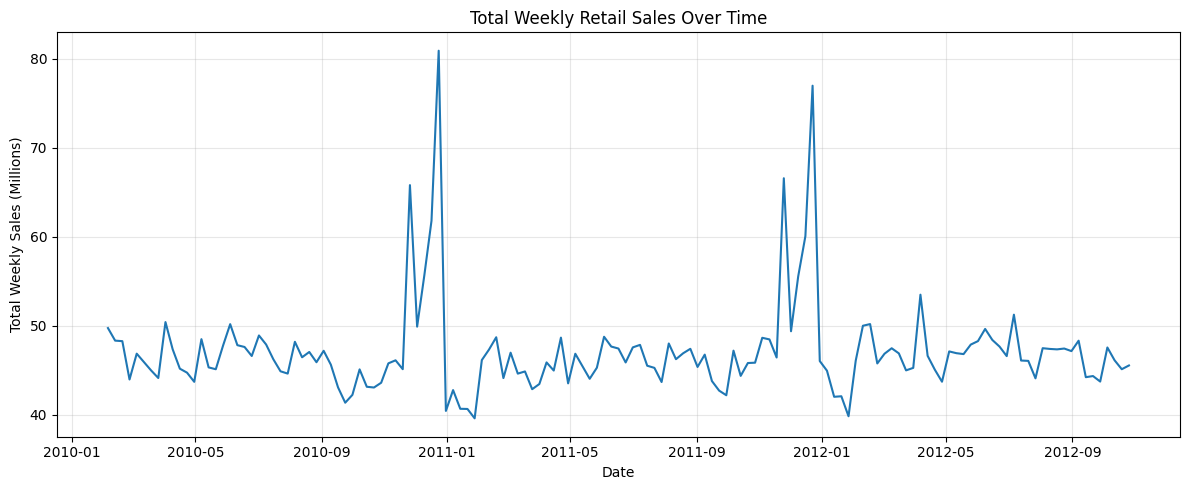

In [9]:
import matplotlib.pyplot as plt

# Plot total weekly sales over time
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_sales["Date"],
    weekly_sales["Weekly_Sales"] / 1_000_000
)

plt.title("Total Weekly Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales (Millions)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Findings

Throughout the majority of the observed timeframe, weekly retail sales demonstrated stability, consistently fluctuating between 43 million and 50 million. 

However the data highlights sharp seasonal peaks near the end of each year at about 81 million in late 2010 and 77 million in late 2011. Which then was followed by a decline in post-holiday sales, that was roughly at 40-46 million. 

 These repeating spikes confirm a strong seasonal influence on consumer buying behavior.

 Recommendation: Retail managers should use predictive historical modelling to ramp up inventory and staffing levels ahead of these predictable high-demand windows.



### 1.4 Sales Performance visualisations

#### Top 10 Stores By Sales Total

This bar chart shows a comparison between the ten stores that have the highest total recorded sales. 

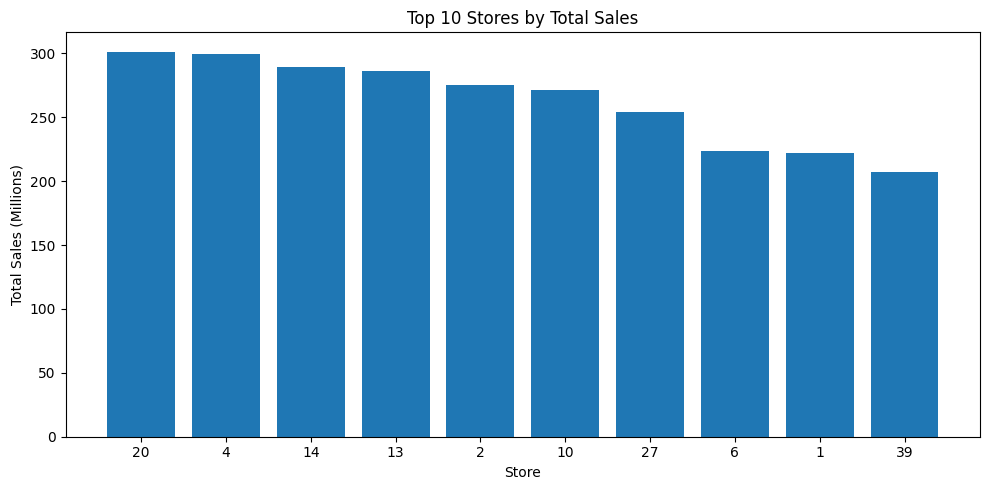

In [10]:
# Visualise the top 10 stores by total sales
top_10_stores = store_sales.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_10_stores["Store"].astype(str),
    top_10_stores["Weekly_Sales"] / 1_000_000
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales (Millions)")
plt.tight_layout()

plt.show()

#### Top 10 Departments By Sales Total

This bar chart shows a comparison between the ten departments that have the highest total recorded sales across all stores. 

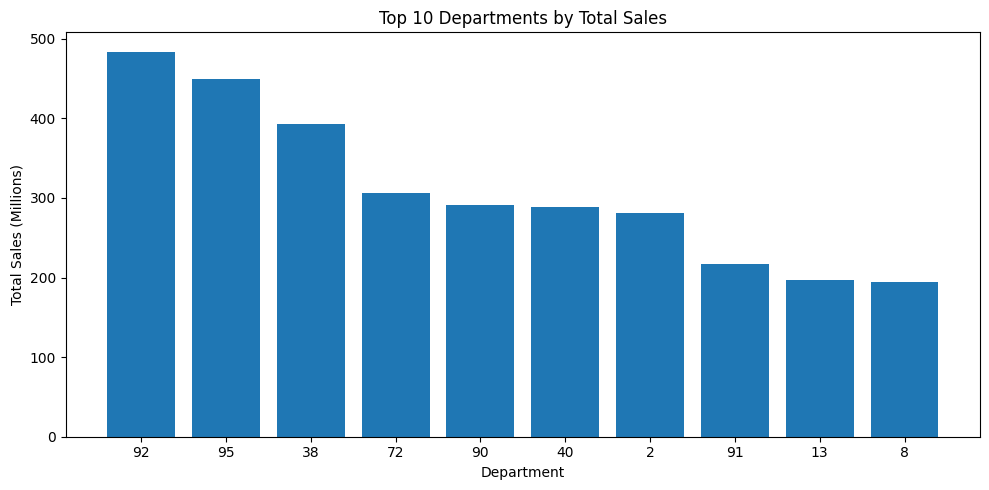

In [11]:
# Visualise the top 10 departments by total sales
top_10_departments = department_sales.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_10_departments["Dept"].astype(str),
    top_10_departments["Weekly_Sales"] / 1_000_000
)

plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Department")
plt.ylabel("Total Sales (Millions)")
plt.tight_layout()

plt.show()

### Business Requirement 1 - Conclusion

This analysis spotted the differences in sales performance across stores, departments and time.

**key Findings**
- Store 20 led total recorded sales at roughly 301.4 million, followed by Stores 4 and 14.

- Department 92 produced the highest total sales at roughly 483.9 million, followed by Departments 95 and 38.

- Overall weekly sales remained steady overall, though sharp seasonal spikes were appearing toward the end of 2010 and 2011. Which suggest recouring seasonal patterns.

**Business Recommendations**
- Leverage insights from top-performing stores and departments to guide inventory planning and resource allocation.

- Anticipate for periods of increased demand by examining historical sales trends.

-  Evaluate differences in store size and underlying regional factors before making direct performance comparisons.

**Limitations** 
Total sales figures to not reflect actual profitability, and identified seasonal spikes do not show the cause, just the patterns. 

